In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 设置中文字体和负号显示
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

road1=Path.cwd()#获取路径,lesson3.ipynb与数据文件同在一个文件夹下
scores_path=(road1/"homework_scores.csv")
student_path=(road1/"homework_students.csv")

scores_data=pd.read_csv(scores_path,encoding="utf-8-sig")
student_data=pd.read_csv(student_path,encoding="utf-8-sig")
print("学生表:",student_data.shape,"成绩表:",scores_data.shape)#输出行数
print("学生表列名:",student_data.columns,"\n成绩表列名:",scores_data.columns)
print(student_data.drop_duplicates().to_string(index=False))#去重，转为str输出
print(scores_data.drop_duplicates().to_string(index=False))

学生表: (8, 6) 成绩表: (16, 3)
学生表列名: Index(['student_id', 'name', 'grade', 'study_hours_per_week',
       'attendance_rate', 'practice_exercises_week'],
      dtype='str') 
成绩表列名: Index(['student_id', 'course', 'score'], dtype='str')
student_id name grade  study_hours_per_week  attendance_rate  practice_exercises_week
       S01   张三    大一                     4             0.80                       18
       S02   李四    大一                     6             0.90                       24
       S03   王五    大一                     5             0.85                       20
       S04   赵六    大二                     8             0.95                       30
       S05   陈晨    大二                     3             0.70                       12
       S06   刘洋    大二                     7             0.88                       26
       S07   孙悦    大三                     9             0.98                       34
       S08   周宁    大三                     2             0.60                       

In [313]:
inner_csv=scores_data.merge(student_data,on="student_id",how="inner",indicator=True)
print(inner_csv)#只保留两边都有的数据

   student_id  course  score name grade  study_hours_per_week  \
0         S01  Python   78.0   张三    大一                     4   
1         S01     统计学   82.0   张三    大一                     4   
2         S02  Python   90.0   李四    大一                     6   
3         S02     统计学   88.0   李四    大一                     6   
4         S03  Python   65.0   王五    大一                     5   
5         S03     统计学    NaN   王五    大一                     5   
6         S04  Python   92.0   赵六    大二                     8   
7         S04     统计学   94.0   赵六    大二                     8   
8         S05  Python   58.0   陈晨    大二                     3   
9         S05     统计学   62.0   陈晨    大二                     3   
10        S06  Python   81.0   刘洋    大二                     7   
11        S06     统计学   79.0   刘洋    大二                     7   
12        S07  Python   96.0   孙悦    大三                     9   
13        S07     统计学   91.0   孙悦    大三                     9   

    attendance_rate  pra

In [314]:
left_csv=student_data.merge(scores_data,on="student_id",how="left",indicator=True)
print(left_csv)#只保留左边的全部数据

   student_id name grade  study_hours_per_week  attendance_rate  \
0         S01   张三    大一                     4             0.80   
1         S01   张三    大一                     4             0.80   
2         S02   李四    大一                     6             0.90   
3         S02   李四    大一                     6             0.90   
4         S03   王五    大一                     5             0.85   
5         S03   王五    大一                     5             0.85   
6         S04   赵六    大二                     8             0.95   
7         S04   赵六    大二                     8             0.95   
8         S05   陈晨    大二                     3             0.70   
9         S05   陈晨    大二                     3             0.70   
10        S06   刘洋    大二                     7             0.88   
11        S06   刘洋    大二                     7             0.88   
12        S07   孙悦    大三                     9             0.98   
13        S07   孙悦    大三                     9             0.9

In [315]:
right_csv=student_data.merge(scores_data,on="student_id",how="right",indicator=True)
print(right_csv)#只保留右边的全部数据

   student_id name grade  study_hours_per_week  attendance_rate  \
0         S01   张三    大一                   4.0             0.80   
1         S01   张三    大一                   4.0             0.80   
2         S02   李四    大一                   6.0             0.90   
3         S02   李四    大一                   6.0             0.90   
4         S03   王五    大一                   5.0             0.85   
5         S03   王五    大一                   5.0             0.85   
6         S04   赵六    大二                   8.0             0.95   
7         S04   赵六    大二                   8.0             0.95   
8         S05   陈晨    大二                   3.0             0.70   
9         S05   陈晨    大二                   3.0             0.70   
10        S06   刘洋    大二                   7.0             0.88   
11        S06   刘洋    大二                   7.0             0.88   
12        S07   孙悦    大三                   9.0             0.98   
13        S07   孙悦    大三                   9.0             0.9

In [316]:
outer_csv=student_data.merge(scores_data,on="student_id",how="outer",indicator=True)
print(outer_csv)#保留两边的全部数据

   student_id name grade  study_hours_per_week  attendance_rate  \
0         S01   张三    大一                   4.0             0.80   
1         S01   张三    大一                   4.0             0.80   
2         S02   李四    大一                   6.0             0.90   
3         S02   李四    大一                   6.0             0.90   
4         S03   王五    大一                   5.0             0.85   
5         S03   王五    大一                   5.0             0.85   
6         S04   赵六    大二                   8.0             0.95   
7         S04   赵六    大二                   8.0             0.95   
8         S05   陈晨    大二                   3.0             0.70   
9         S05   陈晨    大二                   3.0             0.70   
10        S06   刘洋    大二                   7.0             0.88   
11        S06   刘洋    大二                   7.0             0.88   
12        S07   孙悦    大三                   9.0             0.98   
13        S07   孙悦    大三                   9.0             0.9

S09只在成绩表上有,S08只在学生表上有。
只在成绩表的编号只有1个(S09)，但是有两个成绩，连接到学生表时分为python和统计学分别占两行。
inner连接，inner只保留两边都有的键值，在这里就只保留S01-S07的数据，只在成绩表或只在学生表的数据就被排除了。
后续检查成绩的有效性和是否为空值。

In [317]:
course_rows=scores_data.groupby("course")["score"].size()#以course为表头(?)，统计score的列数
print("每门课程行数\n",course_rows.to_string())
course_valid_scores_data=scores_data.groupby("course")["score"].count()#count不计空值
course_sum_score_data=scores_data.groupby("course")["score"].sum()#sum求和
course_average_score_data=scores_data.groupby("course")["score"].mean()#mean求平均
course_median_score_data=scores_data.groupby("course")["score"].median()#median求中位数
print("有效成绩数:\n",course_valid_scores_data.to_string(),"\n学生总分:\n",course_sum_score_data.to_string(),"\n平均分:\n",course_average_score_data.to_string(),"\n中位数:\n",course_median_score_data.to_string())

每门课程行数
 course
Python    8
统计学       8
有效成绩数:
 course
Python    8
统计学       7 
学生总分:
 course
Python    633.0
统计学       572.0 
平均分:
 course
Python    79.125000
统计学       81.714286 
中位数:
 course
Python    79.5
统计学       82.0


如果用.count计数，就不会计入空成绩，相反如果用.size计数，就会把空成绩也算上

In [318]:
student_scores_data=scores_data.groupby("student_id").size()
print("学生课程记录行数\n",student_scores_data.to_string())
student_valid_scores_data=scores_data.groupby("student_id")["score"].count()
student_average_scores_data=scores_data.groupby("student_id")["score"].mean()
print("有效成绩数:\n",student_valid_scores_data.to_string(),"\n平均分:\n",student_average_scores_data.to_string())


学生课程记录行数
 student_id
S01    2
S02    2
S03    2
S04    2
S05    2
S06    2
S07    2
S09    2
有效成绩数:
 student_id
S01    2
S02    2
S03    1
S04    2
S05    2
S06    2
S07    2
S09    2 
平均分:
 student_id
S01    80.0
S02    89.0
S03    65.0
S04    93.0
S05    60.0
S06    80.0
S07    93.5
S09    74.5


In [319]:
S03_score_row=scores_data.groupby("student_id")["course"].get_group("S03").count()
S03_average_score=scores_data.groupby("student_id")["score"].get_group("S03").mean()
S03_course=scores_data.groupby("student_id").get_group("S03")
S03_used=S03_course[S03_course["score"].notna()]
S03_valid_course=S03_used["course"].count()
print("S03课程记录行数:",S03_score_row)
print("S03有效成绩数:",S03_valid_course)
print("S03平均分:",S03_average_score)
print("使用的课程:","".join(S03_used["course"].astype(str)))

S03课程记录行数: 2
S03有效成绩数: 1
S03平均分: 65.0
使用的课程: Python


In [320]:
grade_csv=scores_data.merge(student_data,on="student_id",how="inner",indicator=True)
grade_rows=grade_csv.groupby(["grade","course"])["score"].size().to_string()
print("组合记录行数:\n",grade_rows)
grade_valid_score=grade_csv.groupby(["grade","course"])["score"].count()
print("有效成绩数:\n",grade_valid_score.to_string())
bigone_data=grade_valid_score.groupby(["grade","course"]).get_group(("大一","统计学")).dropna().to_string()
print("大一X统计学有效成绩数:\n",bigone_data)

组合记录行数:
 grade  course
大一     Python    3
       统计学       3
大三     Python    1
       统计学       1
大二     Python    3
       统计学       3
有效成绩数:
 grade  course
大一     Python    3
       统计学       2
大三     Python    1
       统计学       1
大二     Python    3
       统计学       3
大一X统计学有效成绩数:
 grade  course
大一     统计学       2


缺失的成绩会被.size计入行数内，但不会被.count计入有效成绩中

In [321]:
student_valid_scores_frame=student_valid_scores_data.to_frame().rename(columns={"score":"有效成绩数"})
student_average_scores_frame=student_average_scores_data.to_frame().rename(columns={"score":"平均分"})
student_out=student_average_scores_frame.merge(student_valid_scores_frame,on="student_id",how="inner")
finally_csv=student_out.merge(student_data,on="student_id",how="right")
print(finally_csv)

  student_id   平均分  有效成绩数 name grade  study_hours_per_week  attendance_rate  \
0        S01  80.0    2.0   张三    大一                     4             0.80   
1        S02  89.0    2.0   李四    大一                     6             0.90   
2        S03  65.0    1.0   王五    大一                     5             0.85   
3        S04  93.0    2.0   赵六    大二                     8             0.95   
4        S05  60.0    2.0   陈晨    大二                     3             0.70   
5        S06  80.0    2.0   刘洋    大二                     7             0.88   
6        S07  93.5    2.0   孙悦    大三                     9             0.98   
7        S08   NaN    NaN   周宁    大三                     2             0.60   

   practice_exercises_week  
0                       18  
1                       24  
2                       20  
3                       30  
4                       12  
5                       26  
6                       34  
7                       10  


成绩表内没有S08的数据，进行right连接时保留全部成绩表的数据，所以最终表内S08平均分为空。
把空值当作0分会让空值也被计入有效成绩中。

有效成绩总数: 15


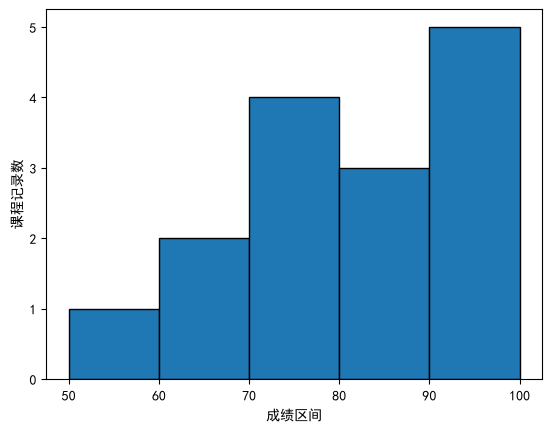

In [322]:
used_score=scores_data["score"]
plt.hist(used_score,bins=5,range=[50,100],edgecolor = "black")
plt.xlabel("成绩区间")
plt.ylabel("课程记录数")
print("有效成绩总数:",student_valid_scores_data.sum())

[90,100]课程记录数最多，有5门，柱子统计的是课程成绩记录

python有效成绩数: 8 中位数: 79.5
统计学有效成绩数: 7 中位数: 82.0


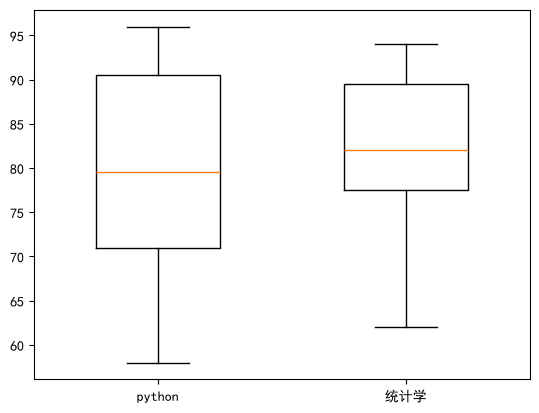

In [323]:
clean_used=scores_data.dropna(subset=["score"])
python_used=clean_used[clean_used["course"]=="Python"]["score"]
tongji_used=clean_used[clean_used["course"]=="统计学"]["score"]
plt.boxplot([python_used,tongji_used],tick_labels=["python","统计学"],widths=0.5)
print("python有效成绩数:",python_used.count(),"中位数:",python_used.median())
print("统计学有效成绩数:",tongji_used.count(),"中位数:",tongji_used.median())


中位线表示数据的中位数。
直方图更适合回答学生成绩的主要分布区间，箱线图更适合回答每个课程成绩的成绩分布区间。
可以，箱线图可以看出统计学的成绩比python的中位数更高，而且分布更加集中，说明统计学大部分人考得不错。

PCA用方差衡量信息量，而方差的数值大小受单位影响。比如study_hours_per_week中如果把小时换算成分钟，数值量级就会变大，从而导致方差变大，此时study_hours_per_week就可能会被当作PC1。

错误的，第一主成分是方差最大的一列，方差大可能只是没标准化所导致的数字大，而非最重要。

解释方差大只能说明数据方差大，解释方差大的成分可能与预测成绩无关。